## ⚙️ **Libraries Import**

In [1]:
# Set seed for reproducibility
SEED = 100

# Import necessary libraries
import os

# Set environment variables before importing modules
os.environ['PYTHONHASHSEED'] = str(SEED)
os.environ['MPLCONFIGDIR'] = os.getcwd() + '/configs/'

# Suppress warnings
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)
warnings.simplefilter(action='ignore', category=Warning)

# Import necessary modules
import logging
import random
import numpy as np
from pathlib import Path


# Set seeds for random number generators in NumPy and Python
np.random.seed(SEED)
random.seed(SEED)

# Import PyTorch
import torch
torch.manual_seed(SEED)
from torch import nn
from torchsummary import summary
from torch.utils.tensorboard import SummaryWriter
import torchvision
from torchvision.transforms import v2 as transforms
from torch.utils.data import TensorDataset, DataLoader
#!pip install torchview
#from torchview import draw_graph

# Configurazione di TensorBoard e directory
#logs_dir = "tensorboard"
#!pkill -f tensorboard
#%load_ext tensorboard
#!mkdir -p models

if torch.cuda.is_available():
    device = torch.device("cuda")
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.benchmark = True
else:
    device = torch.device("cpu")

print(f"PyTorch version: {torch.__version__}")
print(f"Device: {device}")

# Import other libraries
import cv2
import copy
import shutil
from itertools import product
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
from sklearn.model_selection import train_test_split
from PIL import Image
import matplotlib.gridspec as gridspec
import requests
from io import BytesIO

# Configure plot display settings
sns.set(font_scale=1.4)
sns.set_style('white')
plt.rc('font', size=14)
%matplotlib inline

PyTorch version: 2.9.1+cpu
Device: cpu


## 🔧 **Automatic Configuration**

In [2]:
#(LOCAL vs KAGGLE)

def get_paths():
    """It detects the enviroment and returns the correct path."""
    if os.path.exists('/kaggle/input'):
        print("🌍 Detetected enviroment: KAGGLE")
        input_dir = Path('/kaggle/input/datasetcomplete/')
        output_dir = Path('/kaggle/working/')
    else:
        print("💻 Detetected enviroment: LOCAL")
        # Impostate la vostra cartella di input e output locali
        input_dir = Path('../data/archive/')
        output_dir = Path('../data/output/')

        # Crea le cartelle se non esistono in locale
        output_dir.mkdir(parents=True, exist_ok=True)

    return input_dir, output_dir

INPUT_DIR, OUTPUT_DIR = get_paths()
print(f"Input directory: {INPUT_DIR}")
print(f"Output directory: {OUTPUT_DIR}")


💻 Detetected enviroment: LOCAL
Input directory: ..\data\archive
Output directory: ..\data\output


## ⏳ **Data Loading**

In [3]:
def normalize_image(img, standardize=True):

    img = img.astype(np.float32)
    # Se i pixel non sono ancora in [0,1], li scala
    if img.max() > 1.0:
        img = img / 255.0

    if standardize:
        # Media e std ImageNet
        mean = np.array([0.485, 0.456, 0.406])
        std  = np.array([0.229, 0.224, 0.225])
        img = (img - mean) / std

    return img

In [4]:
# I numpy sono nel dataset ora (MESSI SUCCESSIVAMENTE)
train_images = np.load(INPUT_DIR/'train_images.npy')
train_masks = np.load(INPUT_DIR/'train_masks.npy')
test_images = np.load(INPUT_DIR/'test_images.npy')
test_masks = np.load(INPUT_DIR/'test_masks.npy')
train_labels = pd.read_csv(INPUT_DIR/'train_labels.csv')

# Get class names
class_names = train_labels['label']
#print(class_names)

print("Data loaded sucessfully!")
print(f"Train images shape: {train_images.shape}")
print(f"Train masks shape: {train_masks.shape}")
print(f"Test images shape: {test_images.shape}")
print(f"Test masks shape: {test_masks.shape}")
print(f"Train labels shape: {train_labels.shape}")

Data loaded sucessfully!
Train images shape: (1252, 224, 224, 3)
Train masks shape: (1252, 224, 224, 1)
Test images shape: (954, 224, 224, 3)
Test masks shape: (954, 224, 224, 1)
Train labels shape: (1252, 2)


## 🖼️ DATA VISUALIZATION

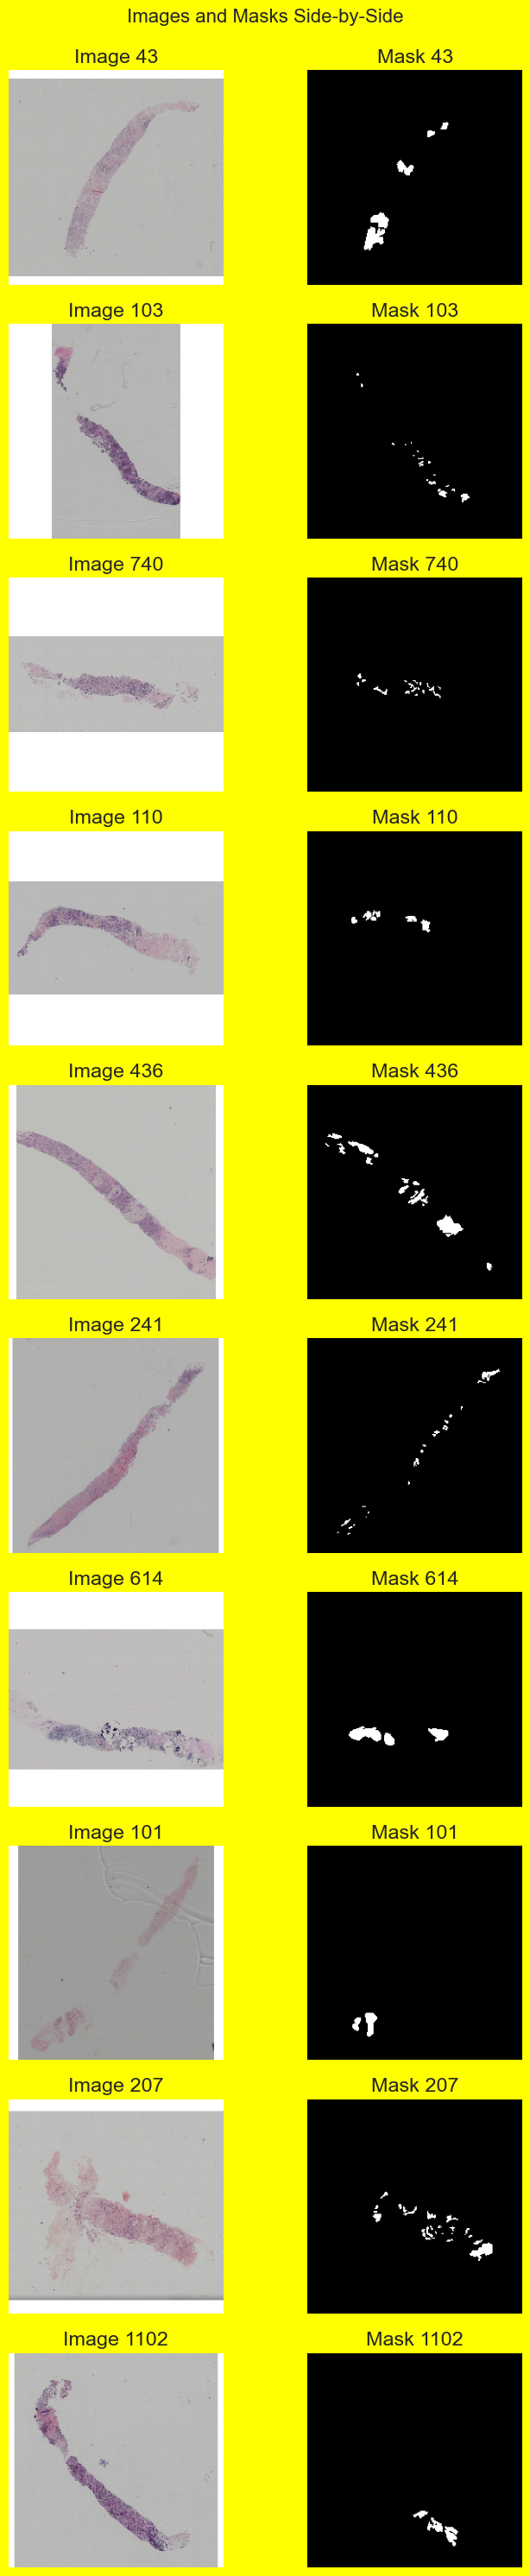

In [5]:
# Number of images to display
num_img = 10

# Select random indices
indices = np.random.choice(len(train_images), num_img, replace=False)

# Display side-by-side comparison (image + mask)
fig, axes = plt.subplots(num_img, 2, figsize=(8, 3 * num_img))
fig.patch.set_facecolor('yellow')  # Sfondo giallo per la figura intera
fig.suptitle('Images and Masks Side-by-Side', fontsize=16, y=0.995)
for i, idx in enumerate(indices):
    # Image on left
    axes[i, 0].imshow(np.clip(train_images[idx], 0, 1))
    axes[i, 0].set_title(f'Image {idx}')
    axes[i, 0].axis('off')
    axes[i, 0].set_facecolor('yellow')  # Sfondo giallo per i subplot

    # Mask on right
    axes[i, 1].imshow(train_masks[idx].squeeze(), cmap='gray')
    axes[i, 1].set_title(f'Mask {idx}')
    axes[i, 1].axis('off')
    axes[i, 1].set_facecolor('yellow')  # Sfondo giallo per i subplot
plt.tight_layout()
plt.show()


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.009703549388482712..255.0].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.17348220538215142..255.0].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.05048353325705299..255.0].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.2784165228591387..255.0].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.29279067095588507..255.0].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.1386939932222922..255.0].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for in

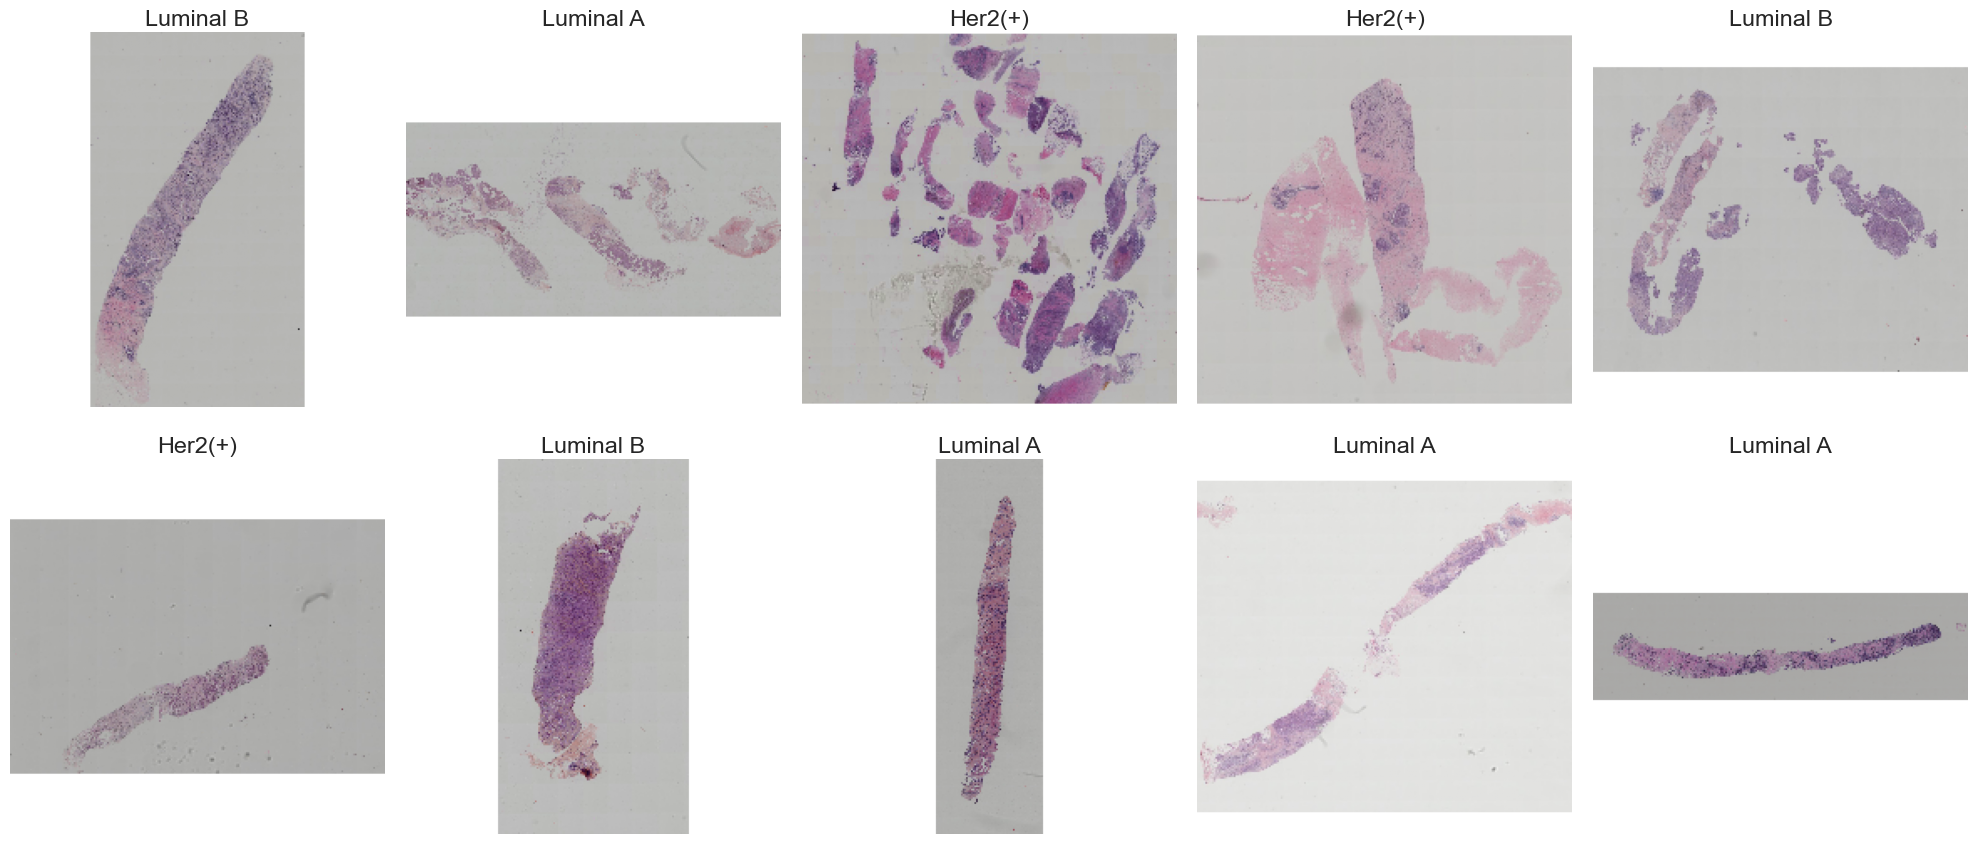

In [6]:
# Number of images to display
num_img = 10

# Select random indices from the training set
random_indices = random.sample(range(len(train_images)), num_img)

# Create subplot layout for images
fig, axes = plt.subplots(2, num_img // 2, figsize=(20, 9))

for i, idx in enumerate(random_indices):
    ax = axes[i // 5, i % 5]

    # Display the image at the selected index (convert CHW to HWC)
    img = train_images[idx]
    ax.imshow(img)

    # Add class name as title
    class_name = class_names[idx]
    class_name = class_name.replace('_', ' ').title()
    ax.set_title(class_name, pad=5)

    # Remove axis lines for clearer display
    ax.axis('off')

# Adjust layout for better spacing
plt.tight_layout()
plt.show()

## 🔎 **Data Analysis**

        sample_index      label
count           1252       1252
unique          1252          4
top     img_1411.png  Luminal B
freq               1        440

--- Unique Labels ---
['Triple negative' 'Luminal A' 'Luminal B' 'HER2(+)']

--- Label Distribution ---
                 count  percentage
label                             
Luminal B          440       35.14
Luminal A          339       27.08
HER2(+)            320       25.56
Triple negative    153       12.22


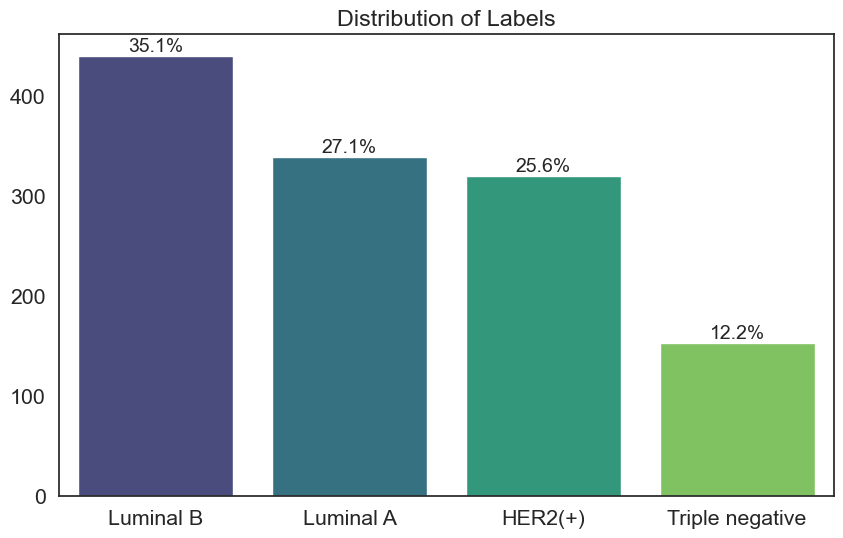

In [7]:
#LABELS ANALYSIS AND DISTRIBUTION
print(train_labels.describe())

print("\n--- Unique Labels ---")
unique_labels = train_labels['label'].unique()
print(unique_labels)

print("\n--- Label Distribution ---")
label_counts = train_labels['label'].value_counts()
label_percentages = train_labels['label'].value_counts(normalize=True) * 100
label_stats = pd.DataFrame({
    'count': label_counts,
    'percentage': label_percentages
})
print(label_stats.round(2))

# Visualize the distribution
plt.figure(figsize=(10, 6))
ax = sns.barplot(x=label_counts.index, y=label_counts.values, hue=label_counts.index, palette='viridis')
plt.title('Distribution of Labels')
plt.xlabel('')
plt.ylabel('')

# Add percentages
total = label_counts.sum()
for p in ax.patches:
    percentage = '{:.1f}%'.format(100 * p.get_height() / total)
    x = p.get_x() + p.get_width() / 2
    y = p.get_height()
    ax.annotate(percentage, (x, y), ha='center', va='bottom')

plt.show()

NUM_CLASSES = len(unique_labels)


## 🔄 **Data Processing**

In [13]:
#PREPARAZIONE DEI TARGET
# Definizione del mapping da label testuale a valore numerico (enum)
label_mapping = {
    'Luminal A': 0,
    'Luminal B': 1,
    'HER2(+)': 2,
    'Triple negative': 3
}
# Aggiunta della nuova colonna 'target' al dataframe train_labels
train_labels['target'] = train_labels['label'].map(label_mapping)
target=np.array(train_labels['target'])

#peso = (numero_totale_training / (numero_classi * numero_per_classe))
class_weights = (len(train_labels)/(NUM_CLASSES*label_stats['count'])).astype(np.float32)

#creating list useful later for tensor transformation
pain_class_weights_list=list(class_weights)
print(f"Pesi bilanciati per classe:\t{pain_class_weights_list}")


Pesi bilanciati per classe:	[0.7113636136054993, 0.9233038425445557, 0.9781249761581421, 2.0457515716552734]
